In [ ]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import myutils

workspace,experiment=myutils.workspace()
from __future__ import annotations

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

In [36]:
# PATHS ---------------------------------------------------------------------- #
adata_file = experiment/'results/pbmc3k_metrics.h5ad'
adata = ad.read_h5ad(adata_file)
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

In [37]:
# SETTINGS ------------------------------------------------------------------- #
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80,facecolor='white', frameon=False)

# Define outliers by MAD

In [38]:
# OUTLIER DEFINITION --------------------------------------------------------- #
from scipy.stats import median_abs_deviation


def get_thresholds(adata, metric: str, nmads: int, round:bool=False, dtype=tuple):
    M = adata.obs[metric]
    bottom = np.median(M) - nmads * median_abs_deviation(M)
    top = np.median(M) + nmads * median_abs_deviation(M)
    if round: bottom, top = np.round(bottom,1), np.round(top,1)
    if dtype==tuple: return bottom, top
    elif dtype==str: return f'[{bottom},{top}]'
    else: dtype((bottom,top))

def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]
    bottom, top = get_thresholds(adata=adata,metric=metric,nmads=nmads)
    outlier = (M < bottom) | (top < M)
    return outlier

In [39]:
# CREATE OUTLIER OBS COL ----------------------------------------------------- #
def flag_outlier_reasons(
    adata, 
    outlier_reason_map:dict,
    colors:dict|None=None,
    nmads:int=5, 
    pass_label="Pass",
    multiple_label="Multiple Metrics",
    ):
    """
    Computes outliers for metrics in outlier_reason_map and creates
    a descriptive 'outlier_reason' column in adata.obs.

    outlier threshold based on median +/- nmads * MAD
    """
    masks = {}
    for metric, caller in outlier_reason_map.items():
        masks[caller] = is_outlier(adata, metric, nmads)

    # rows: cells, columns: outlier results
    df_masks = pd.DataFrame(masks, index=adata.obs_names)
    fail_counts = df_masks.sum(axis=1) # count fails per cell
    new_lists = df_masks.apply(lambda x: [col for col,v in zip(x.index,x) if v], axis=1)

    if len(outlier_reason_map) > 1:
        multiple_strings = (
            multiple_label + " (" + fail_counts.astype(str) + ")"
        )
        new_reasons = np.where(
            fail_counts == 0, 
            pass_label,
            np.where(
                fail_counts == 1,
                df_masks.idxmax(axis=1), # Returns the column name where True is located
                # multiple_strings
                multiple_label
            )
        )
    else:
        single_metric_name = next(iter(outlier_reason_map.values()))
        new_reasons = np.where(fail_counts == 0, pass_label, single_metric_name)

    if ("outlier_reason" in adata.obs and "outlier_reason_list" in adata.obs):
        final_lists = [
            old + new for old, new in zip(adata.obs["outlier_reason_list"], new_lists)
        ]
        final_reasons = [
            pass_label if len(lst) == 0 else
            lst[0] if len(lst) == 1 else
            multiple_label
            for lst in final_lists
        ]
        old_colors = {cat:color for cat,color in zip(adata.obs["outlier_reason"].cat.categories,adata.uns['outlier_reason_colors'])}
        old_colors.update(colors)
        colors = old_colors
        adata.obs["outlier_reason"] = pd.Categorical(final_reasons, categories=list(colors))
        adata.obs["outlier_reason_list"] = final_lists
    else:
        adata.obs["outlier_reason"] = pd.Categorical(new_reasons, categories=list(colors))
        adata.obs["outlier_reason_list"] = new_lists
        # adata.obs["outlier_reason"] = pd.Categorical(reasons)
    if colors!=None: 
        adata.uns["outlier_reason_colors"] = [
            colors[cat] for cat in adata.obs["outlier_reason"].cat.categories
            ]
    return adata

def find_reason(df,search:list,mode='and',col="outlier_reason_list"):
    if not isinstance(search,list): search=[search]
    possible = np.unique(np.concatenate(outlier_reasons['outlier_reason_list'].values))
    for s in search:
        if s not in possible: print(f"search term '{s}' is not possible and will be removed.")
    search = [s for s in search if s in possible]
    if mode=='and': return df[df[col].apply(lambda x: sum(v in search for v in x)==len(search))]
    elif mode=='or': return df[df[col].apply(lambda x: any(v in search for v in x))]

In [40]:
# OUTLIER REASONS ------------------------------------------------------------ #
#  
# Count Depth: 
# Detected Genes: 
# Top 20 Genes:
# 
# Mitochondrial:
# Ribosomal:
# ---------------------------------------------------------------------------- #

PASS_LABEL = "Pass"
MULTIPLE_LABEL = "Multiple Metrics"
outlier_reason_map = {
    'log1p_total_counts':'Count Depth',
    'log1p_n_genes_by_counts':'Detected Genes',
    # 'pct_counts_in_top_20_genes':'Top 20 Genes',
    }
metric_colors = {
    PASS_LABEL: "#D3D3D3", # Light Grey
    MULTIPLE_LABEL: "#26090a", # Purple
    'Count Depth': "#AE6DE3",  # Red
    'Detected Genes': "#377EB8",  # Blue
    # 'Top 20 Genes': "#FF7F00",  # Orange
}

n=5
metrics = list(zip(outlier_reason_map,[n]*len(outlier_reason_map)))
adata_plot = adata.copy()
adata_plot = flag_outlier_reasons(adata_plot,outlier_reason_map,metric_colors,nmads=n,pass_label=PASS_LABEL,multiple_label=MULTIPLE_LABEL)

outlier_reason_map = {
    'pct_counts_mt':'Mitochondrial',
    'pct_counts_ribo':'Ribosomal',
    'pct_counts_hb':'Hemoglobin',
    }
metric_colors = {
    PASS_LABEL: "#D3D3D3", # Light Grey
    MULTIPLE_LABEL: "#26092a", # Purple
    'Mitochondrial': "#1fa115",  # Green
    'Ribosomal': "#f903f1",  # Pink
    'Hemoglobin': "#E41A1C",  # Red
}
n=5 # ? stricter rules like n=3
metrics = metrics+list(zip(outlier_reason_map,[n]*len(outlier_reason_map)))
adata_plot = flag_outlier_reasons(adata_plot,outlier_reason_map,metric_colors,nmads=n,pass_label=PASS_LABEL,multiple_label=MULTIPLE_LABEL)

more_metrics = ['total_counts','n_genes_by_counts']
metrics = metrics+list(zip(more_metrics,[n]*len(more_metrics)))
outlier_reasons = adata_plot.obs[['outlier_reason','outlier_reason_list']+[m[0] for m in metrics]]

for metric,n in metrics:
    print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True,str))

metrics = metrics+list(zip(outlier_reason_map,[n]*len(outlier_reason_map)))


log1p_total_counts outliers: 58 [6.599999904632568,8.800000190734863]
log1p_n_genes_by_counts outliers: 79 [5.9,7.5]
pct_counts_mt outliers: 76 [-0.699999988079071,4.699999809265137]
pct_counts_ribo outliers: 0 [-0.699999988079071,43.599998474121094]
pct_counts_hb outliers: 29 [0.0,0.0]
total_counts outliers: 92 [-298.0,4692.0]
n_genes_by_counts outliers: 89 [159.5,1474.5]


In [41]:
# SAVE OUTLIER REASONS ------------------------------------------------------- #
outlier_reasons.to_csv(experiment/'results/pbmc3k_outlier_reasons.csv')
outlier_reasons

,outlier_reason,outlier_reason_list,log1p_total_counts,log1p_n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,total_counts,n_genes_by_counts
AAACATACAACCAC-1,Pass,[],7.792349,6.661855,3.015283,24.741842,0.0,2421.0,781
AAACATTGAGCTAC-1,Pass,[],8.497807,7.210080,3.793596,23.985313,0.0,4903.0,1352
AAACATTGATCAGC-1,Pass,[],8.055158,7.031741,0.889171,18.037472,0.0,3149.0,1131
AAACCGTGCTTCCG-1,Pass,[],7.878534,6.867974,1.743085,15.081470,0.0,2639.0,960
AAACCGTGTATGCG-1,Pass,[],6.889591,6.259581,1.223242,10.193680,0.0,981.0,522
...,...,...,...,...,...,...,...,...,...
TTTCGAACTCTCAT-1,Pass,[],8.149602,7.052721,2.109217,15.255706,0.0,3461.0,1155
TTTCTACTGAGGCA-1,Pass,[],8.145550,7.113142,0.928343,21.148825,0.0,3447.0,1227
TTTCTACTTCCTCG-1,Pass,[],7.429521,6.434547,2.197150,24.049881,0.0,1684.0,622
TTTGCATGAGAGGC-1,Pass,[],6.932448,6.120297,2.050781,16.601562,0.0,1024.0,454


In [42]:
print(outlier_reasons.shape)
outlier_reasons.head(1)

(2700, 9)


,outlier_reason,outlier_reason_list,log1p_total_counts,log1p_n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,total_counts,n_genes_by_counts
AAACATACAACCAC-1,Pass,[],7.792349,6.661855,3.015283,24.741842,0.0,2421.0,781


In [43]:
# RESEARCH SPECIFIC CELL ----------------------------------------------------- #
# adata_qc : outliers are removed
# adata : keeps all cells but has obs where you can see which cell would be deemed outlier
# outliers : is a anndata object that stores those exact outliers and information why its an outlier
# ---------------------------------------------------------------------------- #
cell = adata.obs.iloc[10].name
print(outlier_reasons.loc[cell][:2])
cell = adata.obs.iloc[500].name
print(outlier_reasons.loc[cell][:2])
outlier_reasons.loc['AACAGCACAAGAGT-1'][:2]

outlier_reason         Pass
outlier_reason_list      []
Name: AAACTTGAAAAACG-1, dtype: object
outlier_reason         Pass
outlier_reason_list      []
Name: AGGATAGAGGATTC-1, dtype: object


outlier_reason                      Multiple Metrics
outlier_reason_list    [Count Depth, Detected Genes]
Name: AACAGCACAAGAGT-1, dtype: object

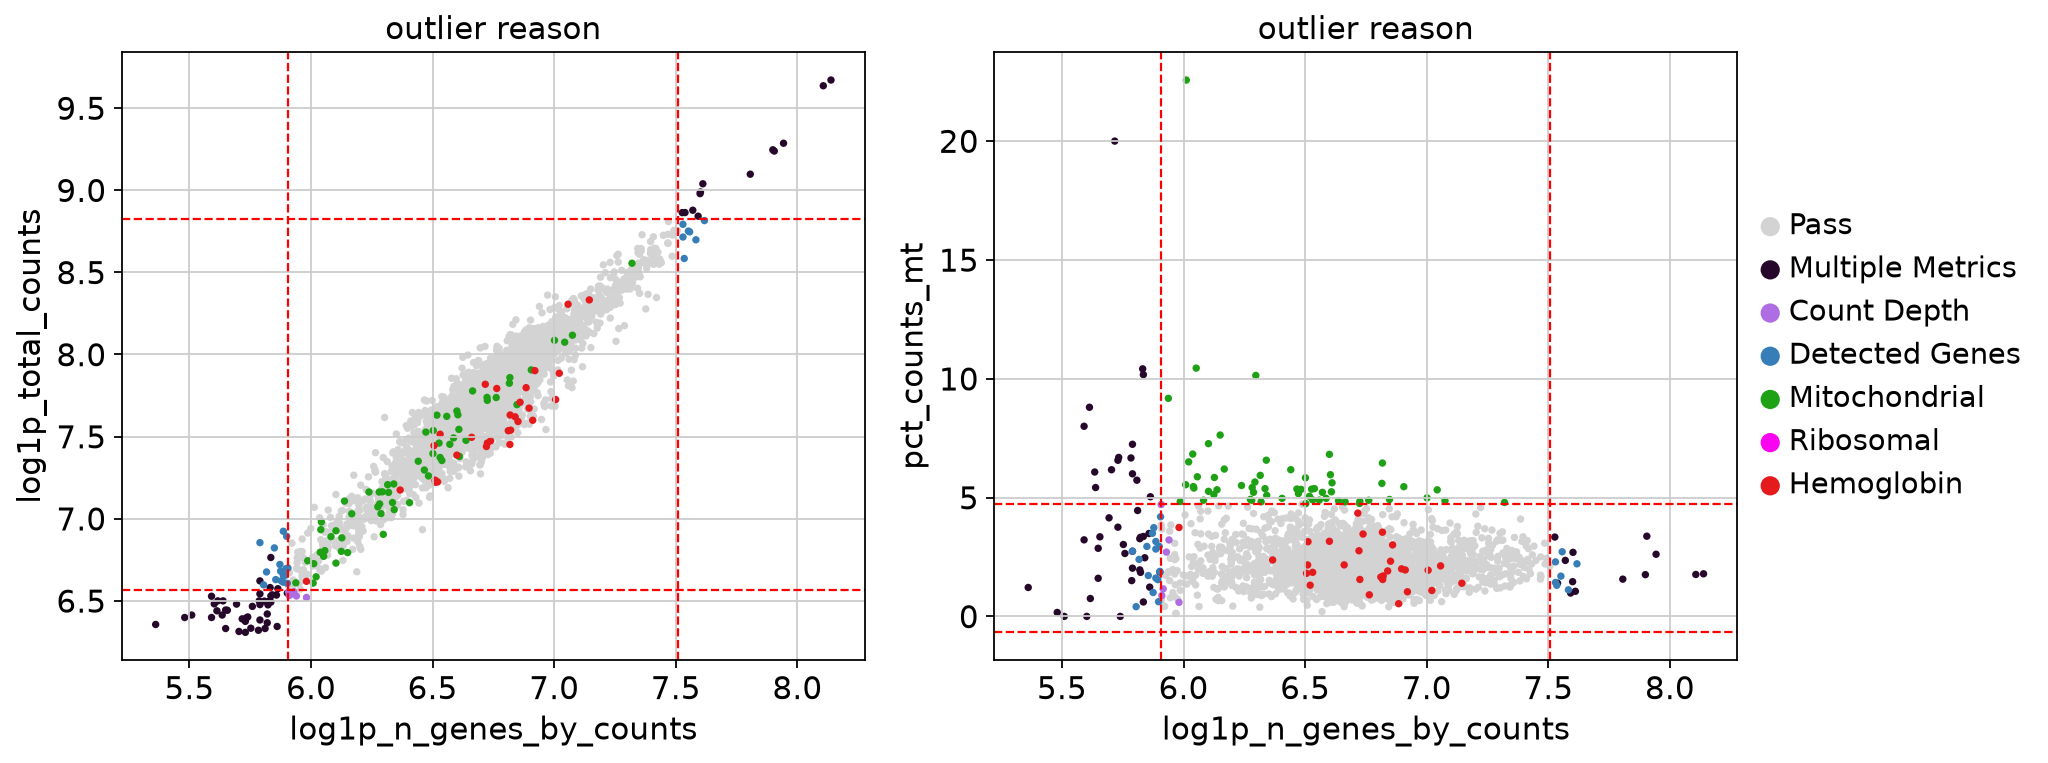

In [44]:
# PLOT OUTLIERS -------------------------------------------------------------- #

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

sc.pl.scatter(adata_plot, "log1p_n_genes_by_counts", "log1p_total_counts",color='outlier_reason',show=False, ax=ax1)
n=5
if ax1.get_legend():
    ax1.get_legend().remove()
ax1.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",n),ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax1.hlines(y=get_thresholds(adata,"log1p_total_counts",n),xmin=0, xmax=1,transform=ax1.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)
sc.pl.scatter(adata_plot, "log1p_n_genes_by_counts", "pct_counts_mt",color='outlier_reason',show=False, ax=ax2)
n=5
ax2.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",n),ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax2.hlines(y=get_thresholds(adata,"pct_counts_mt",n),xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig(experiment /'figures/outliers/pbmc3k_multiple_metrics_out.png', bbox_inches='tight')
plt.show()


# mad thresholds

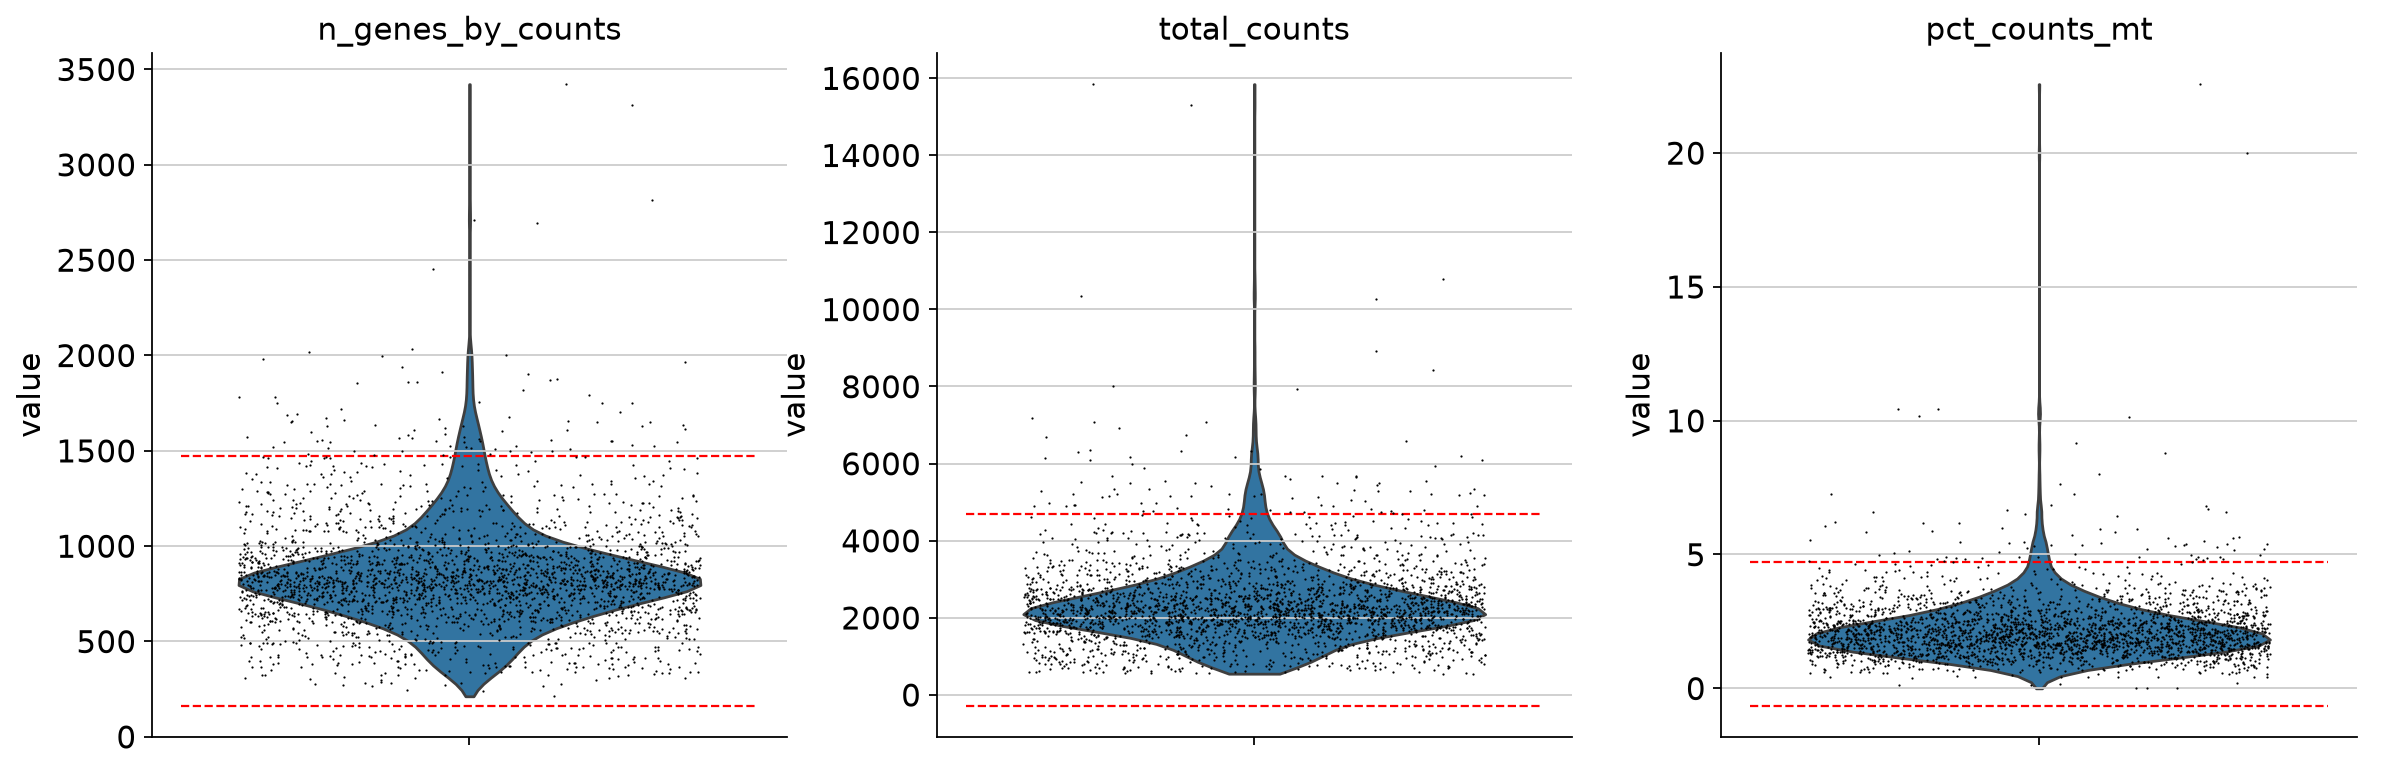

In [45]:
 # COUNT DISTRIBUTIONS -------------------------------------------------------- #
grid = sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show = False,
)
axes = grid.axes.flatten()

axes[0].hlines(
    y=get_thresholds(adata, "n_genes_by_counts", n),
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
axes[1].hlines(
    y=get_thresholds(adata, "total_counts", n),
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
axes[2].hlines(
    y=get_thresholds(adata, "pct_counts_mt", n),
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
plt.savefig(experiment/'figures/outliers/pbmc3k_log1p_count_metrics_out.png', bbox_inches='tight')
plt.show()

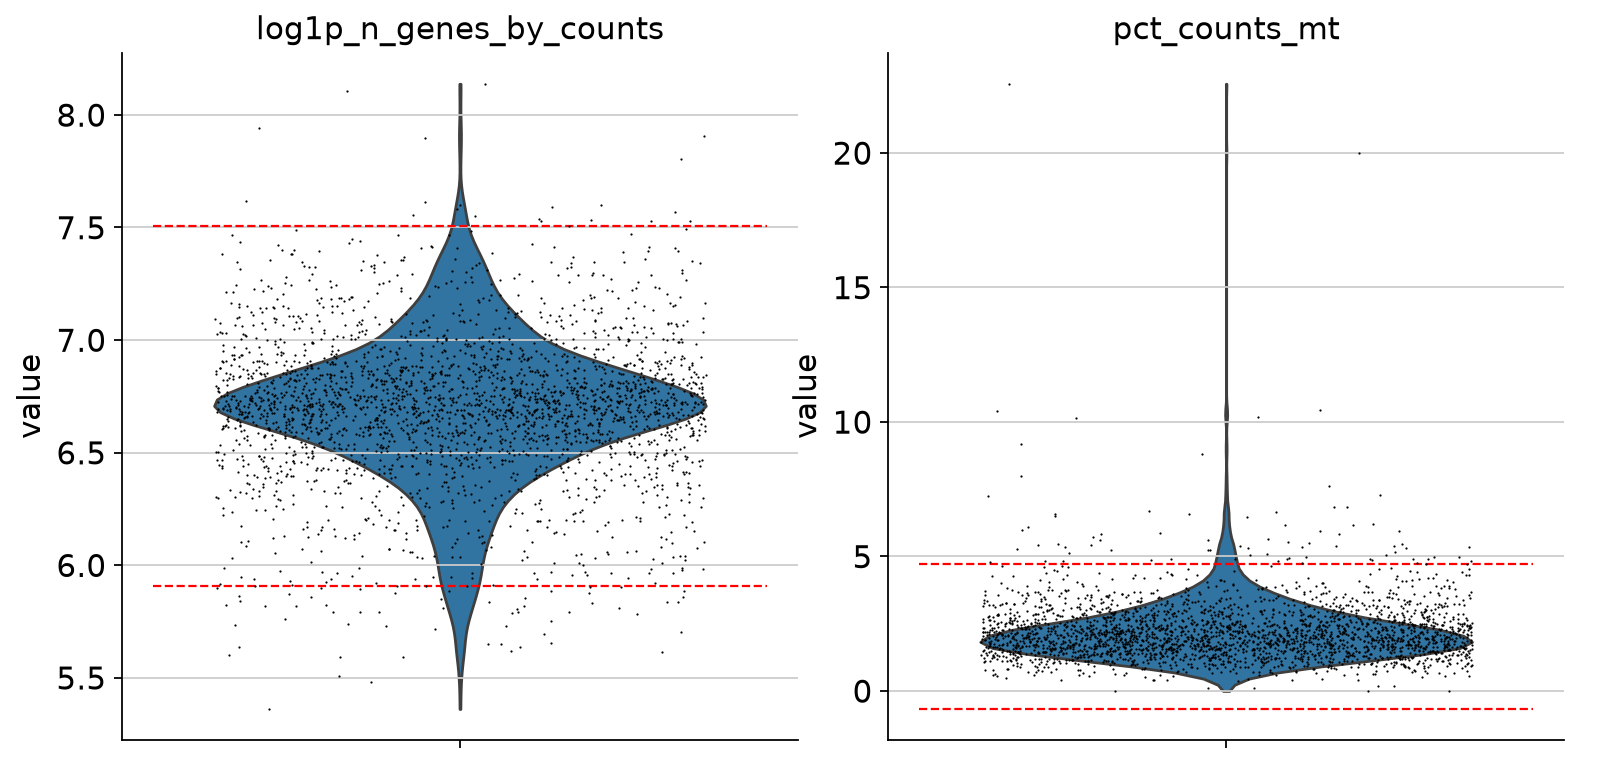

In [46]:
 # COUNT DISTRIBUTIONS -------------------------------------------------------- #
grid = sc.pl.violin(
    adata,
    ["log1p_n_genes_by_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show = False,
)
axes = grid.axes.flatten()

axes[0].hlines(
    y=get_thresholds(adata, "log1p_n_genes_by_counts", n),
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
axes[1].hlines(
    y=get_thresholds(adata, "pct_counts_mt", n),
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
plt.savefig(experiment/'figures/outliers/pbmc3k_mt_ribo_hb_out.png')
plt.show()

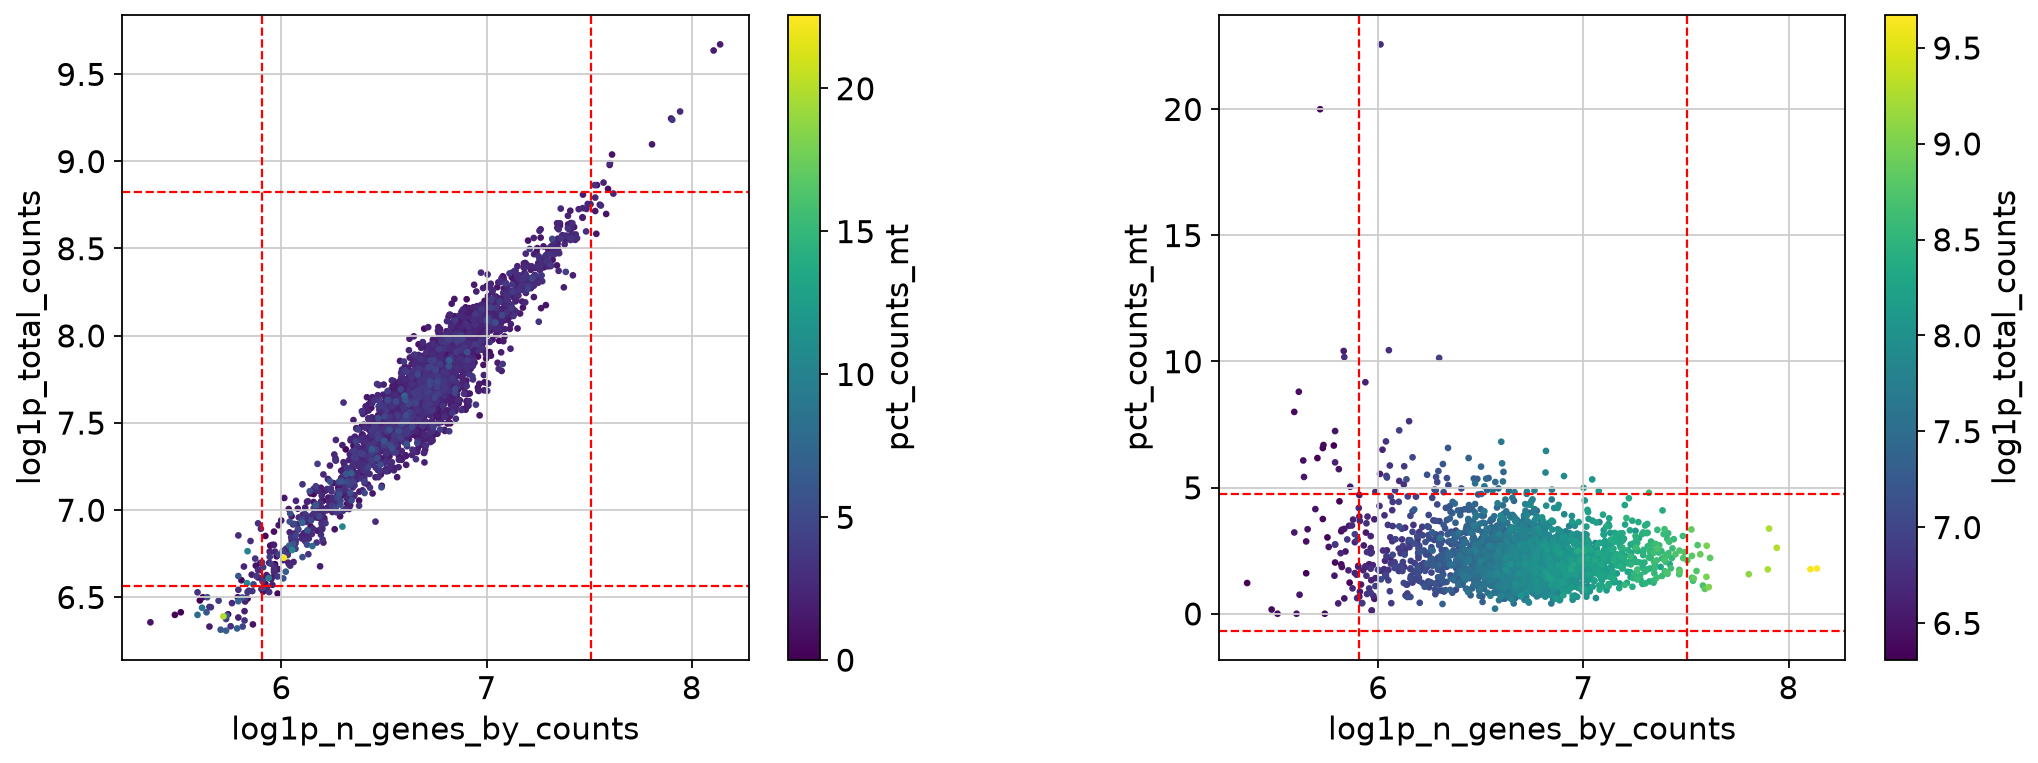

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
df1 = adata.obs[["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"]].sort_values("pct_counts_mt")

ax1.scatter(
    df1["log1p_n_genes_by_counts"], 
    df1["log1p_total_counts"], 
    c=df1["pct_counts_mt"], 
    cmap="viridis", 
    s=4, # Adjust point size
)
fig.colorbar(ax1.collections[0], ax=ax1, label='pct_counts_mt')
ax1.set_xlabel("log1p_n_genes_by_counts")
ax1.set_ylabel("log1p_total_counts")

n=5
ax1.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",n),ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax1.hlines(y=get_thresholds(adata,"log1p_total_counts",n),xmin=0, xmax=1,transform=ax1.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)

df2 = adata.obs[["log1p_n_genes_by_counts", "pct_counts_mt", "log1p_total_counts"]].sort_values("log1p_total_counts")

ax2.scatter(
    df2["log1p_n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=df2["log1p_total_counts"], 
    cmap="viridis", 
    s=4,
)
fig.colorbar(ax2.collections[0], ax=ax2, label='log1p_total_counts')
ax2.set_xlabel("log1p_n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")

n=5
ax2.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",n),ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax2.hlines(y=get_thresholds(adata,"pct_counts_mt",n),xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)


plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
# plt.savefig(experiment/"figures/qc_metric_scatter_plots.png")
plt.savefig(experiment /'figures/outliers/qc_metric_log1p_scatter_plots_out.png', bbox_inches='tight')
plt.show()

# scanpy workflow

In [48]:
adata_sc = adata.copy()
adata_sc

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

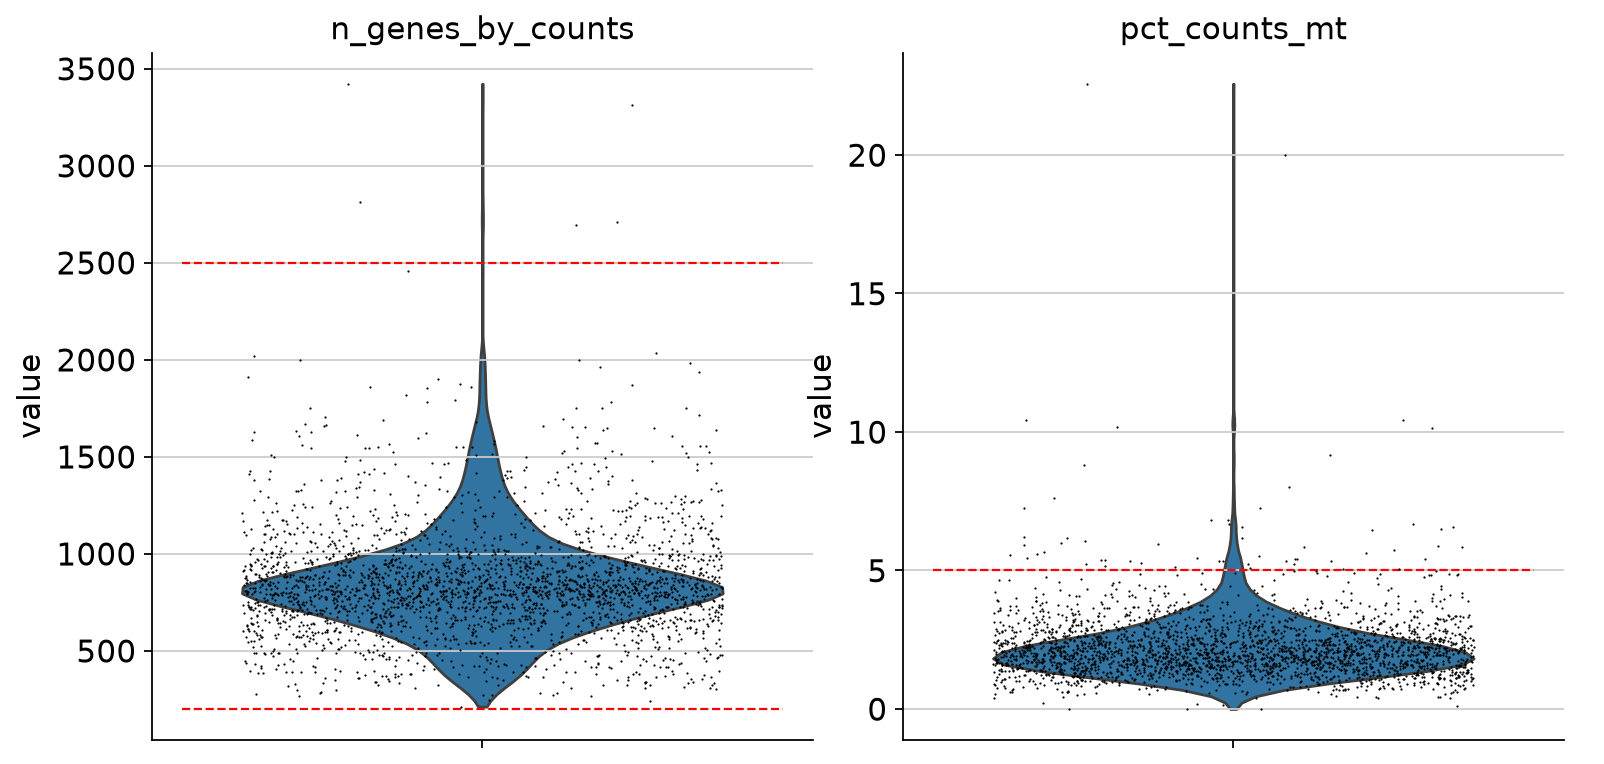

In [49]:
 # COUNT DISTRIBUTIONS -------------------------------------------------------- #
grid = sc.pl.violin(
    adata_sc,
    ["n_genes_by_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show = False,
)
axes = grid.axes.flatten()

axes[0].hlines(
    y=[200,2500],
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
axes[1].hlines(
    y=[5],
    xmin=-0.5, xmax=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
)
plt.savefig(experiment/'figures/outliers/pbmc3k_mt_ribo_hb_out_scanpy.png')
plt.show()

In [50]:
# FILTER --------------------------------------------------------------------- #
sc.pp.filter_cells(adata_sc, min_genes=200) 
sc.pp.filter_genes(adata_sc, min_cells=3) 

filtered out 19024 genes that are detected in less than 3 cells


In [51]:
scanpy_outliers = adata_sc.obs.query('n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5')
adata_sc.obs['outlier'] = adata.obs.index.isin(scanpy_outliers.index)
adata_sc_qc = adata_sc[~adata_sc.obs.index.isin(scanpy_outliers.index)]
print(adata_sc_qc)

print(f"""
The scanpy definition for outliers: 
n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5
number of outliers: {scanpy_outliers.shape[0]}""")

View of AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

The scanpy definition for outliers: 
n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5
number of outliers: 62


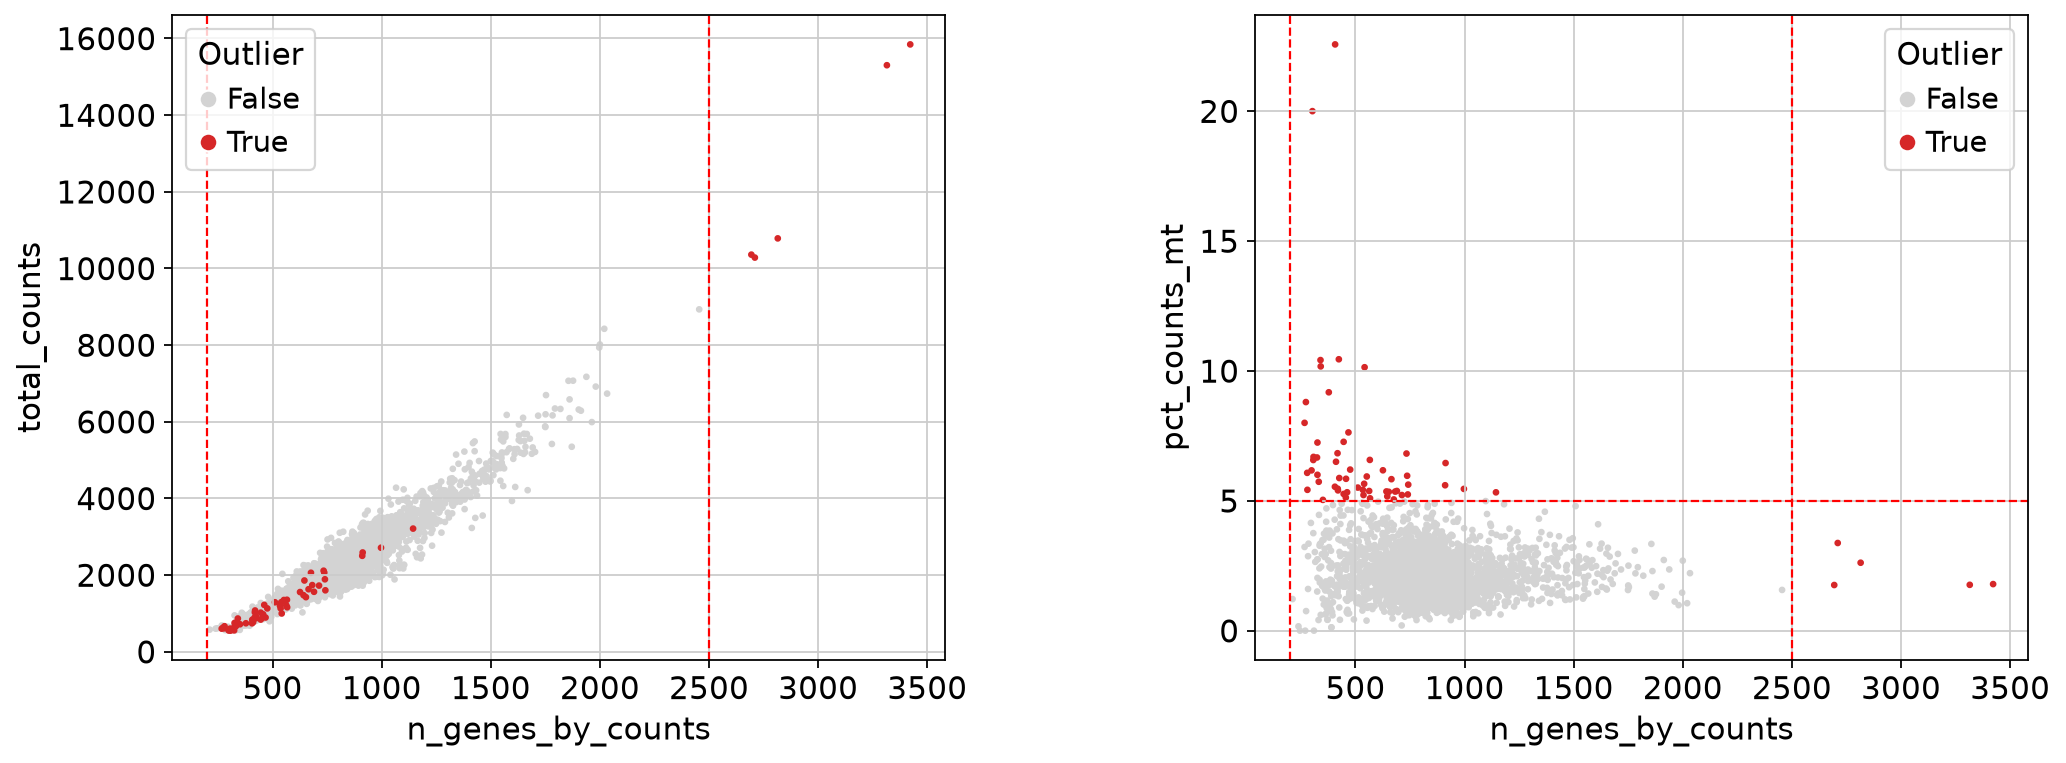

In [52]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

df1 = adata_sc.obs[["outlier", "n_genes_by_counts", "total_counts", "pct_counts_mt"]].copy()
color_map = {"False": "#D3D3D3", "True": "#d62728"}
df1["outlier_str"] = df1["outlier"].astype(str)
df1 = df1.sort_values("outlier_str") 
colors1 = df1["outlier_str"].map(color_map)

ax1.scatter(
    df1["n_genes_by_counts"], 
    df1["total_counts"], 
    c=colors1, 
    s=4, # Adjust point size
)
ax1.set_xlabel("n_genes_by_counts")
ax1.set_ylabel("total_counts")
ax1.vlines(x=[200,2500],ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
handles1 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax1.legend(handles1, color_map.keys(), title="Outlier")

df2 = adata_sc.obs[["outlier", "n_genes_by_counts", "pct_counts_mt", "total_counts"]].copy()
df2["outlier_str"] = df2["outlier"].astype(str)
df2 = df2.sort_values("outlier_str")
colors2 = df2["outlier_str"].map(color_map)

sc2 = ax2.scatter(
    df2["n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=colors2, 
    s=4
)
ax2.set_xlabel("n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
ax2.vlines(x=[200,2500],ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax2.hlines(y=[5],xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)
handles2 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax2.legend(handles2, color_map.keys(), title="Outlier")

plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/outliers/pbmc3k_scanpy_outliers.png")
plt.show()

# my workflow

In [53]:
adata_qc = adata.copy()
adata_qc

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

In [54]:
# FILTER --------------------------------------------------------------------- #
sc.pp.filter_cells(adata_qc, min_genes=200) 
sc.pp.filter_genes(adata_qc, min_cells=3) 

filtered out 19024 genes that are detected in less than 3 cells


In [55]:
adata_sc

AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

In [56]:
search = ['Detected Genes','Mitochondrial']
outlier_cells = find_reason(outlier_reasons,search,'or')

adata.obs['outlier'] = adata.obs.index.isin(outlier_cells.index)
adata_qc.obs['outlier'] = adata_qc.obs.index.isin(outlier_cells.index)
adata_qc = adata_qc[~adata_qc.obs.index.isin(outlier_cells.index)]

print(f"""
\nThe scanpy definition for outliers: 
n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5
number of outliers: {scanpy_outliers.shape[0]}
\nMy definition for outliers:
Based on: {', '.join(search)}
number of outliers: {outlier_cells.shape[0]}""")
try: 
    outlier_cells.loc[scanpy_outliers.index]
    print("""\t! Contains all outliers from scanpy definition\n""")
except:
    print("""\t! scanpy defines other outliers\n""")




The scanpy definition for outliers: 
n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5
number of outliers: 62

My definition for outliers:
Based on: Detected Genes, Mitochondrial
number of outliers: 140
	! Contains all outliers from scanpy definition



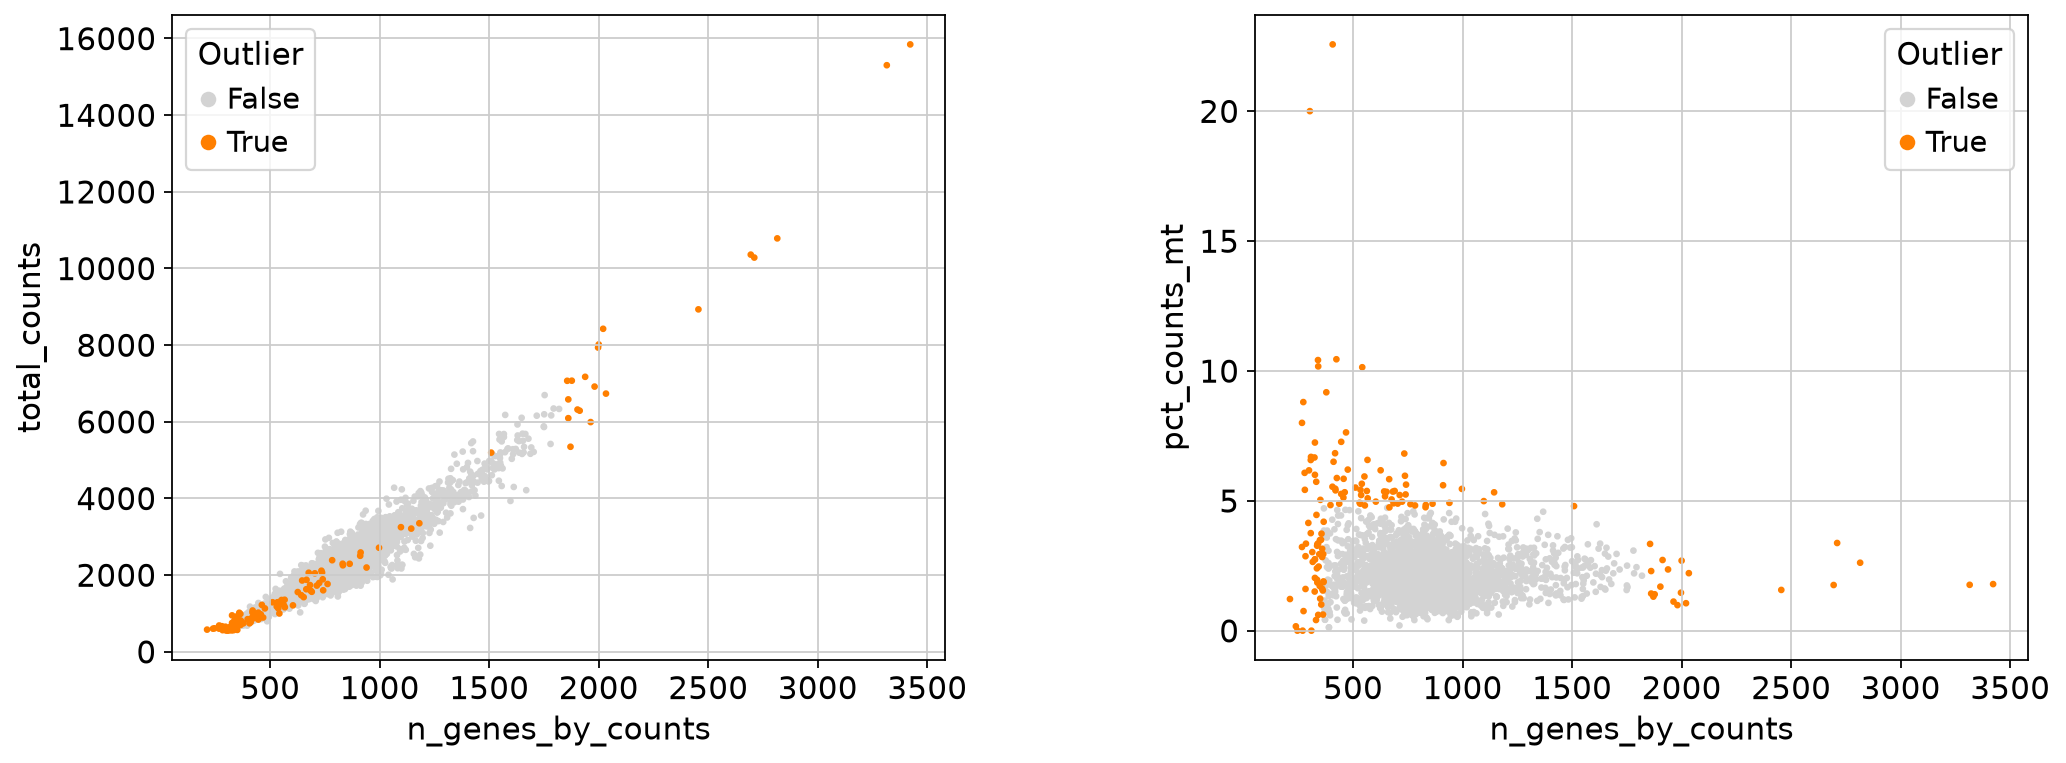

In [57]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

df1 = adata.obs[["outlier", "n_genes_by_counts", "total_counts", "pct_counts_mt"]].copy()
color_map = {"False": "#D3D3D3", "True": "#FF7F00"}
df1["outlier_str"] = df1["outlier"].astype(str)
df1 = df1.sort_values("outlier_str") 
colors1 = df1["outlier_str"].map(color_map)

ax1.scatter(
    df1["n_genes_by_counts"], 
    df1["total_counts"], 
    c=colors1, 
    s=4, # Adjust point size
)
ax1.set_xlabel("n_genes_by_counts")
ax1.set_ylabel("total_counts")
handles1 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax1.legend(handles1, color_map.keys(), title="Outlier")

df2 = adata.obs[["outlier", "n_genes_by_counts", "pct_counts_mt", "total_counts"]].copy()
df2["outlier_str"] = df2["outlier"].astype(str)
df2 = df2.sort_values("outlier_str")
colors2 = df2["outlier_str"].map(color_map)

sc2 = ax2.scatter(
    df2["n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=colors2, 
    s=4
)
ax2.set_xlabel("n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
handles2 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax2.legend(handles2, color_map.keys(), title="Outlier")

plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/outliers/pbmc3k_my_outliers.png")
plt.show()

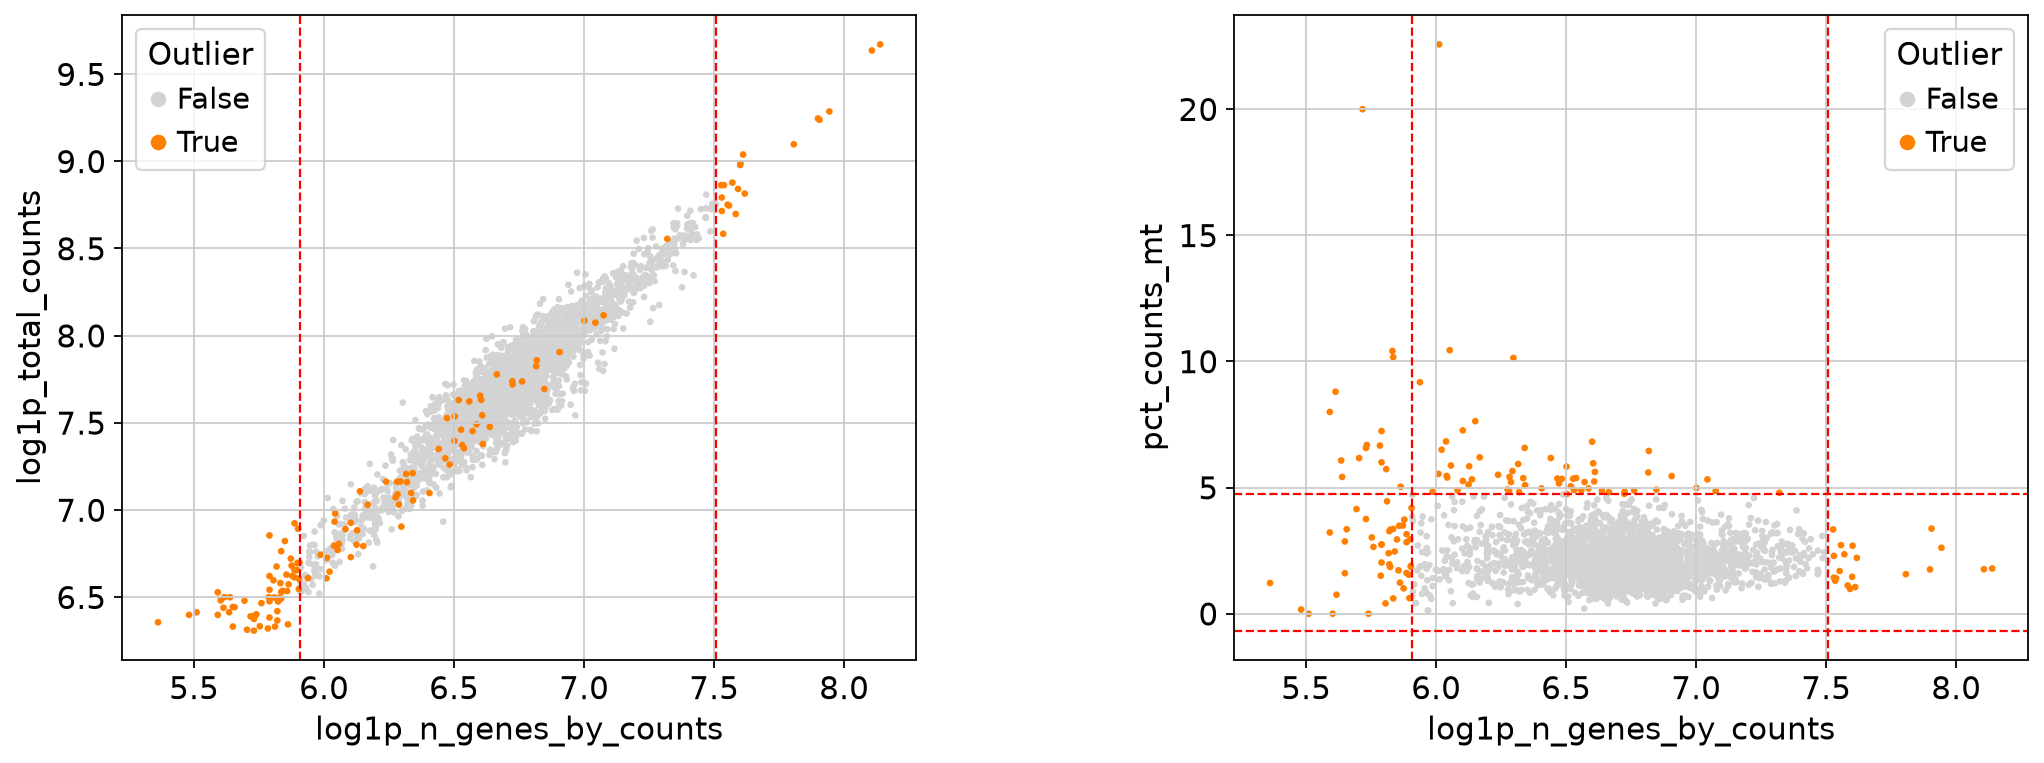

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

df1 = adata.obs[["outlier", "log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"]].copy()
color_map = {"False": "#D3D3D3", "True": "#FF7F00"}
df1["outlier_str"] = df1["outlier"].astype(str)
df1 = df1.sort_values("outlier_str") 
colors1 = df1["outlier_str"].map(color_map)

ax1.scatter(
    df1["log1p_n_genes_by_counts"], 
    df1["log1p_total_counts"], 
    c=colors1, 
    s=4, # Adjust point size
)
ax1.set_xlabel("log1p_n_genes_by_counts")
ax1.set_ylabel("log1p_total_counts")
ax1.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",nmads=n),ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)

handles1 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax1.legend(handles1, color_map.keys(), title="Outlier")

df2 = adata.obs[["outlier", "log1p_n_genes_by_counts", "pct_counts_mt", "log1p_total_counts"]].copy()
df2["outlier_str"] = df2["outlier"].astype(str)
df2 = df2.sort_values("outlier_str")
colors2 = df2["outlier_str"].map(color_map)

sc2 = ax2.scatter(
    df2["log1p_n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=colors2, 
    s=4
)
n=5
ax2.set_xlabel("log1p_n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
ax2.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",nmads=n),ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax2.hlines(y=get_thresholds(adata,"pct_counts_mt",nmads=n),xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)

handles2 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax2.legend(handles2, color_map.keys(), title="Outlier")


plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/outliers/pbmc3k_log_my_outliers.png")
plt.show()

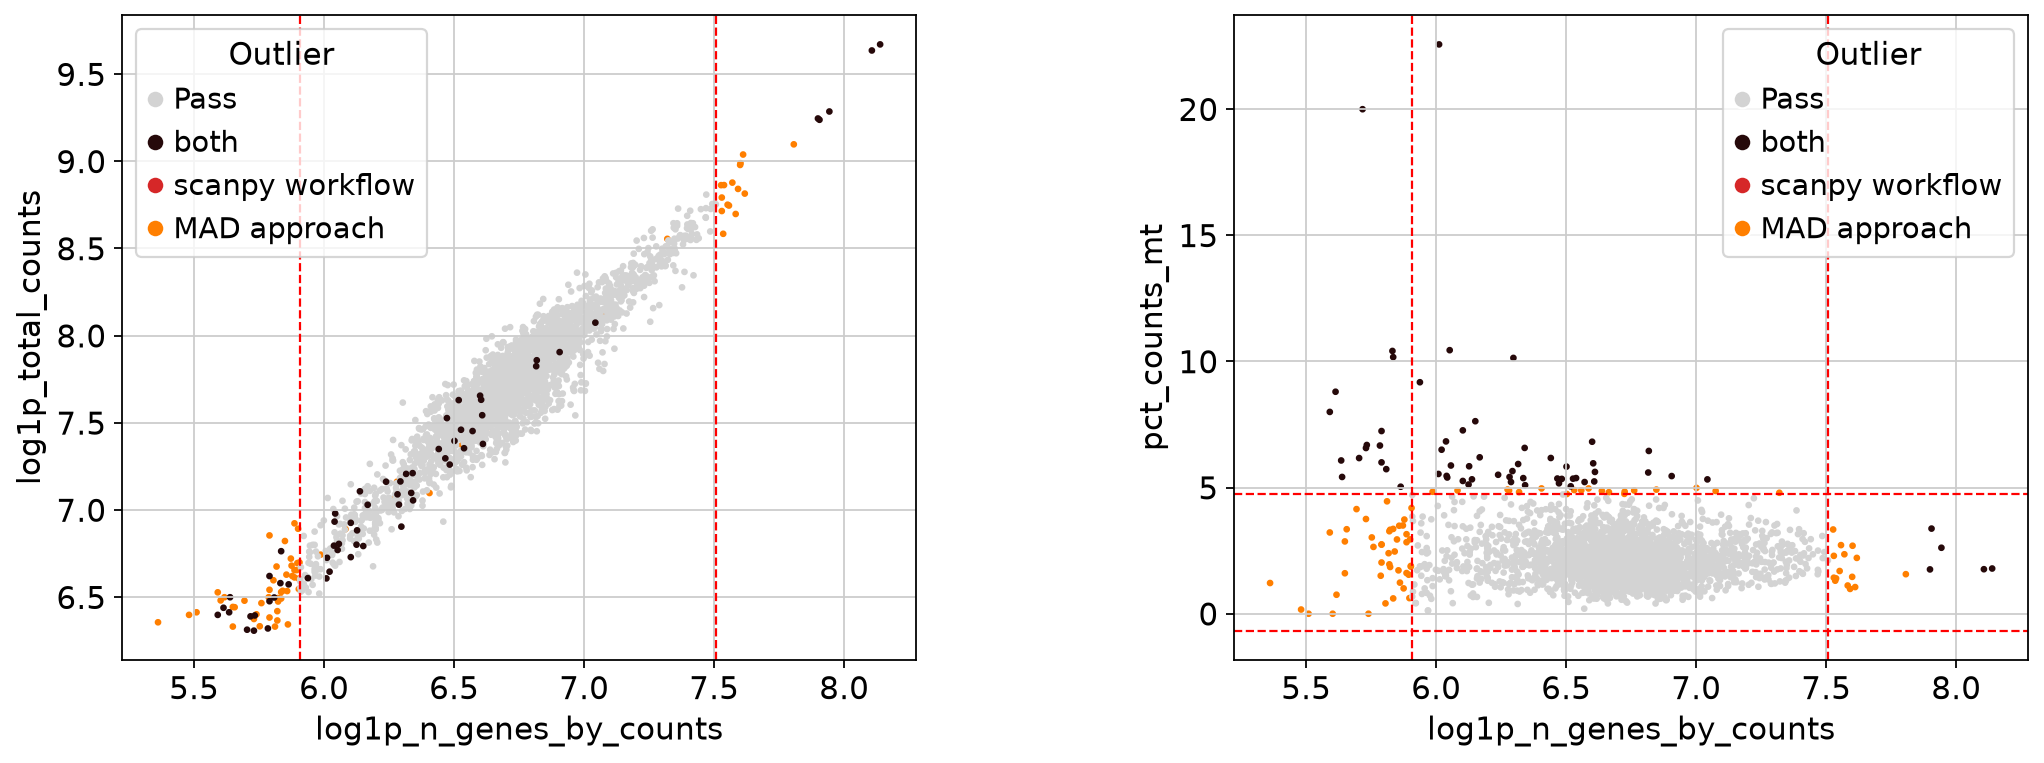

In [59]:
adata_plot = adata.copy()
is_sc = adata_plot.obs.index.isin(scanpy_outliers.index)
is_my = adata_plot.obs.index.isin(outlier_cells.index)
conditions = [
    is_sc & is_my,  # Present in both
    is_sc,  # Present only in df1
    is_my,  # Present only in df2
]
choices = ["both", "scanpy workflow", "MAD approach"]
adata_plot.obs["outlier"] = np.select(conditions, choices, default="Pass")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

df1 = adata_plot.obs[["outlier", "log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"]].copy()
color_map = {"Pass": "#D3D3D3", "both": "#26090a", "scanpy workflow": "#d62728", "MAD approach": "#FF7F00"}
df1["outlier_str"] = df1["outlier"].astype(str)
df1 = df1.sort_values("outlier_str") 
colors1 = df1["outlier_str"].map(color_map)

ax1.scatter(
    df1["log1p_n_genes_by_counts"], 
    df1["log1p_total_counts"], 
    c=colors1, 
    s=4, # Adjust point size
)
ax1.set_xlabel("log1p_n_genes_by_counts")
ax1.set_ylabel("log1p_total_counts")
ax1.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",nmads=n),ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
handles1 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax1.legend(handles1, color_map.keys(), title="Outlier")
handles2 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax2.legend(handles2, color_map.keys(), title="Outlier")

df2 = adata_plot.obs[["outlier", "log1p_n_genes_by_counts", "pct_counts_mt", "log1p_total_counts"]].copy()
df2["outlier_str"] = df2["outlier"].astype(str)
df2 = df2.sort_values("outlier_str")
colors2 = df2["outlier_str"].map(color_map)

sc2 = ax2.scatter(
    df2["log1p_n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=colors2, 
    s=4
)
n=5
ax2.set_xlabel("log1p_n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
ax2.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",nmads=n),ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax2.hlines(y=get_thresholds(adata,"pct_counts_mt",nmads=n),xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)

plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/outliers/pbmc3k_log_my_outliers.png")
plt.show()

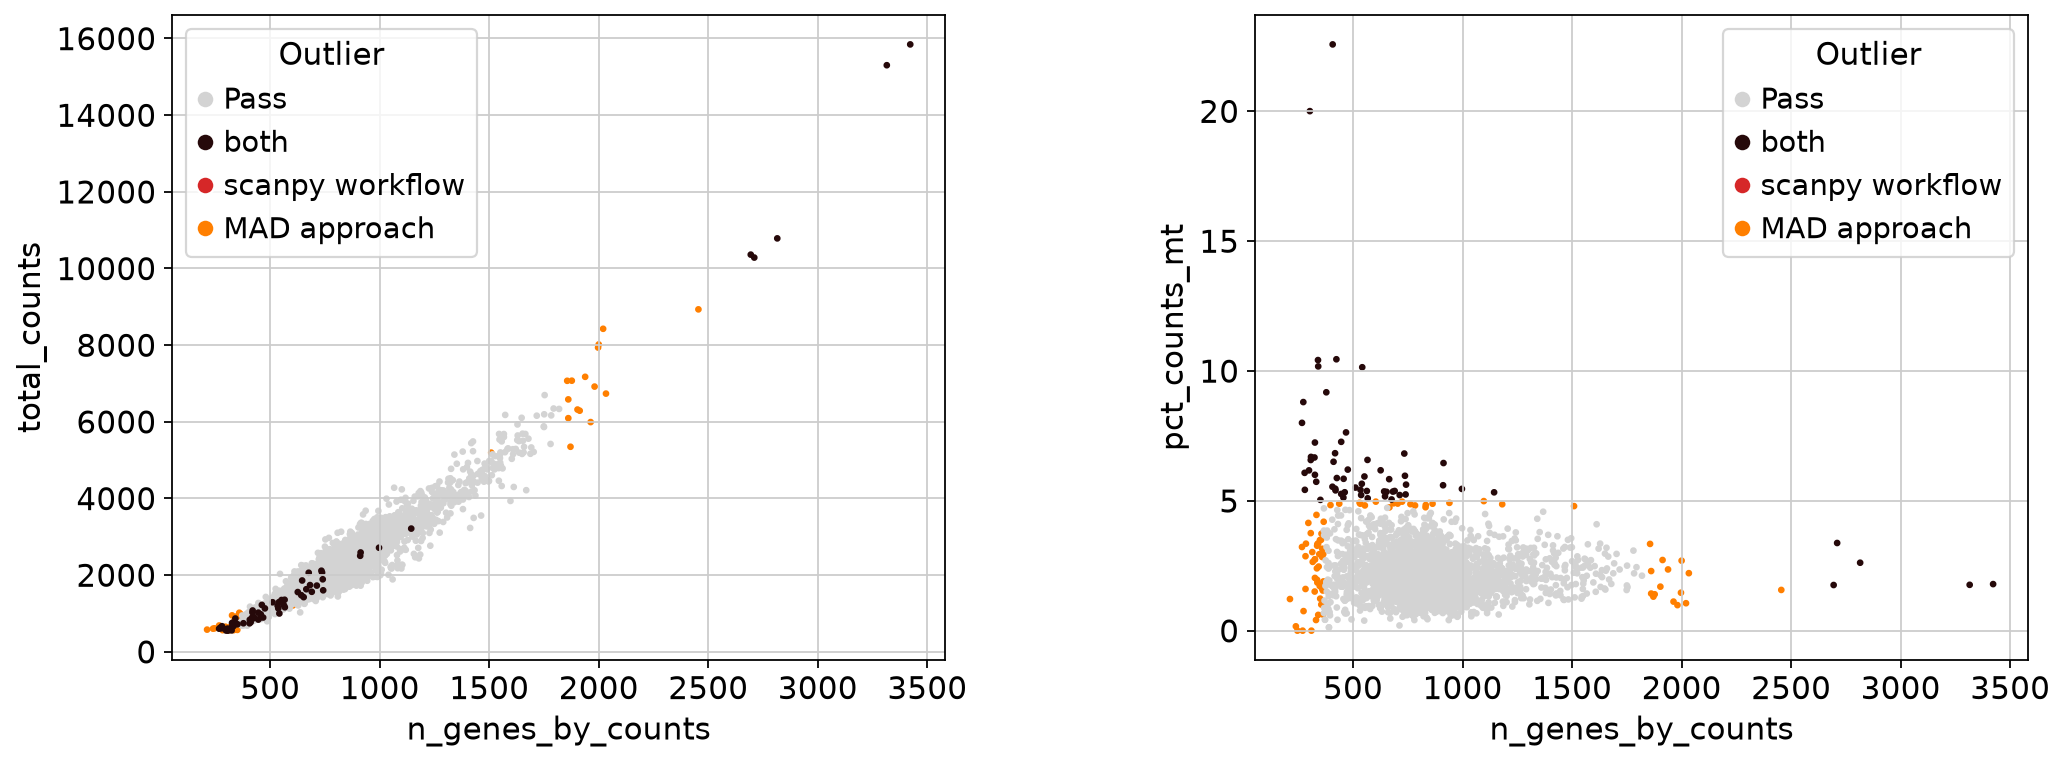

In [60]:
adata_plot = adata.copy()
is_sc = adata_plot.obs.index.isin(scanpy_outliers.index)
is_my = adata_plot.obs.index.isin(outlier_cells.index)
conditions = [
    is_sc & is_my,  # Present in both
    is_sc,  # Present only in df1
    is_my,  # Present only in df2
]
choices = ["both", "scanpy workflow", "MAD approach"]
adata_plot.obs["outlier"] = np.select(conditions, choices, default="Pass")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

df1 = adata_plot.obs[["outlier", "n_genes_by_counts", "total_counts", "pct_counts_mt"]].copy()
color_map = {"Pass": "#D3D3D3", "both": "#26090a", "scanpy workflow": "#d62728", "MAD approach": "#FF7F00"}
df1["outlier_str"] = df1["outlier"].astype(str)
df1 = df1.sort_values("outlier_str") 
colors1 = df1["outlier_str"].map(color_map)

ax1.scatter(
    df1["n_genes_by_counts"], 
    df1["total_counts"], 
    c=colors1, 
    s=4, # Adjust point size
)
ax1.set_xlabel("n_genes_by_counts")
ax1.set_ylabel("total_counts")
# ax1.vlines(x=[200,2500],ymin=0, ymax=1,transform=ax1.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
handles1 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax1.legend(handles1, color_map.keys(), title="Outlier")
handles2 = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[cat], markersize=8) for cat in color_map]
ax2.legend(handles2, color_map.keys(), title="Outlier")

df2 = adata_plot.obs[["outlier", "n_genes_by_counts", "pct_counts_mt", "total_counts"]].copy()
df2["outlier_str"] = df2["outlier"].astype(str)
df2 = df2.sort_values("outlier_str")
colors2 = df2["outlier_str"].map(color_map)

sc2 = ax2.scatter(
    df2["n_genes_by_counts"], 
    df2["pct_counts_mt"], 
    c=colors2, 
    s=4
)
n=5
ax2.set_xlabel("n_genes_by_counts")
ax2.set_ylabel("pct_counts_mt")
# ax2.vlines(x=[200,2500],ymin=0, ymax=1,transform=ax2.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
# ax2.hlines(y=[5],xmin=0, xmax=1,transform=ax2.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)

plt.tight_layout() 
fig.subplots_adjust(wspace=0.4)
plt.savefig(experiment/"figures/outliers/pbmc3k_my_outliers.png")
plt.show()

# Save Result

In [61]:
adata.obs["outlier"].sum()

np.int64(140)

In [62]:
adata_qc

View of AnnData object with n_obs × n_vars = 2560 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

In [63]:
adata_sc_qc

View of AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

In [64]:
adata_qc

View of AnnData object with n_obs × n_vars = 2560 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X)

In [65]:
adata_sc_qc.write(experiment/"results/scanpy_workflow/pbmc3k_sc_qc.h5ad")
adata_qc.write(experiment/"results/mad_workflow/pbmc3k_mad_qc.h5ad")

# Doublets

In [77]:
adata.shape[0], adata.obs.predicted_doublet.sum()

(2700, np.int64(32))

In [78]:
adata_sc_qc.shape[0], adata_sc_qc.obs.predicted_doublet.sum()

(2638, np.int64(31))

In [79]:
adata_qc.shape[0], adata_sc_qc.obs.predicted_doublet.sum()

(2560, np.int64(31))